### Good executions vs. tips with a skill-trained video encoder (SkillFormer-Ego)

`good_tip_cca.ipynb` found that zero-shot Qwen3.5-4B video embeddings can't tell good-execution moments from
tips-for-improvement moments on held-out takes, and that a CCA with the experts' text doesn't improve proficiency
probes. Two explanations: mean-pooled Qwen states keep *what* is happening but not *how well*, or the moment labels
themselves can't be separated from video (37% of moments share their exact second with an opposite-polarity
moment, 58% share an identical 20-frame window, 93% have one within 20 s).

Here the same analysis runs on **SkillFormer-Ego** (TimeSformer-base K600 + LoRA, attentive projector, 4-way
proficiency head), which was fine-tuned for proficiency on the train takes. Its native input is 64 frames, every 4th
frame at 30 FPS (7.5 FPS, 8.5 s). Features per window: the TimeSformer's mean token at layer 6 and at the last layer,
the projector output (the classifier's input), and the 4 logits.

* Moment window: the 64 frames (8.5 s) ending 1 s after the timestamp.
* Take: back-to-back 64-frame tiles, averaged.
* Every held-out evaluation on train splits folds **by participant** (not take), and the test set is the same 164
  SkillFormer test takes. Caveat: SkillFormer saw the train takes' proficiency labels, so its train-take features
  are fit to them; only the test numbers are fair.

In [1]:
import ast
import json
from collections import Counter, defaultdict
from pathlib import Path

import av
import numpy as np

# Same takes as the earlier idea_1 notebooks: video and transcribed expert commentary, train / SkillFormer test split.
DATA_ROOT = next(
    p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir()
)
ANNOTATION_ROOT = DATA_ROOT / "annotations"
COMMENTARY_ROOT = ANNOTATION_ROOT / "expert_commentary"
WINDOW_FPS = 1

LEVELS = {
    "Novice": 1,
    "Early Expert": 2,
    "Intermediate Expert": 3,
    "Late Expert": 4,
}

def take_name(m):
    return m["video_paths"]["ego"].split("/")[1]

def video_path(m):
    parts = m["video_paths"]["ego"].split("/")
    parts[-1:-1] = ["downscaled", "448"]
    return DATA_ROOT.joinpath(*parts)

def has_commentary(take):
    """Whether any expert recorded transcribed commentary on the take (the take set of the earlier notebooks)."""
    for data_path in (COMMENTARY_ROOT / take).rglob("data.json"):
        transcript_path = data_path.parent / "transcriptions.json"
        if not transcript_path.exists():
            continue
        data = json.loads(data_path.read_text(encoding="utf-8"))
        transcripts = json.loads(transcript_path.read_text(encoding="utf-8"))
        if any(transcripts.get(a.get("recording_path"), {}).get("text", "").strip() for a in data.get("annotations", [])):
            return True
    return False

def num_seconds(path):
    """Number of 1 FPS frames decode_1fps() gets from the video (frames 0, 30, 60, ... at 30 FPS)."""
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        step = round(float(stream.average_rate) / WINDOW_FPS)
        return (stream.frames - 1) // step + 1

with open("models/SkillFormer/annotation_test.jsonl", encoding="utf-8") as file:
    test_takes = {json.loads(line)["video_paths"][0].split("/")[1] for line in file}

def split_clips(split):
    annotation_file = "proficiency_demonstrator_train.json" if split == "train" else "proficiency_demonstrator_val.json"
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        metadata = json.load(file)["annotations"]
    clips = []
    for m in metadata:
        if split == "test" and take_name(m) not in test_takes:
            continue
        if not video_path(m).exists() or not has_commentary(take_name(m)):
            continue
        clips.append({"take_name": take_name(m), "scenario": m["scenario_name"], "score": LEVELS[m["proficiency_score"]],
                      "participant": m["origin_participant_id"], "video": str(video_path(m)),
                      "seconds": num_seconds(video_path(m))})
    return clips

clips_by_split = {split: split_clips(split) for split in ("train", "test")}
clips = clips_by_split["test"]
clip_of = {clip["take_name"]: clip for split_list in clips_by_split.values() for clip in split_list}
for split, split_list in clips_by_split.items():
    print(f"{split}: {len(split_list)} takes, {sum(c['seconds'] for c in split_list) / 3600:.1f} h of video")

# Good executions (polarity 1) and tips for improvement (polarity 0) of those takes. Each entry's "list" is a Python
# list literal of sentences (NaN for a few blank entries, which are dropped).
POLARITIES = {"good_executions": (1, "Good execution"), "tips_for_improvement": (0, "Tip for improvement")}

def entry_sentences(entry):
    if not isinstance(entry.get("list"), str):
        return []
    try:
        items = ast.literal_eval(entry["list"])
    except (ValueError, SyntaxError):
        items = [entry["list"]]
    return [s.strip() for s in (items if isinstance(items, list) else [items]) if isinstance(s, str) and s.strip()]

demonstration = {}
for annotation_file in ("proficiency_demonstration_train.json", "proficiency_demonstration_val.json"):
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        demonstration.update({take_name(m): m for m in json.load(file)["annotations"]})

moments = []
for split, split_list in clips_by_split.items():
    for clip in split_list:
        m = demonstration.get(clip["take_name"])
        for key, (polarity, tag) in POLARITIES.items():
            for entry in (m or {}).get(key, []):
                sentences = entry_sentences(entry)
                if sentences:
                    moments.append({"split": split, "take_name": clip["take_name"], "scenario": clip["scenario"],
                                    "polarity": polarity, "time": float(entry["video_time"]), "expert": entry["expert_uid"],
                                    "text": f"{tag}: {' '.join(sentences)}"})
covered = {m["take_name"] for m in moments}
for split in ("train", "test"):
    split_moments = [m for m in moments if m["split"] == split]
    print(f"{split}: {sum(c['take_name'] in covered for c in clips_by_split[split])} takes with moments, "
          f"{sum(m['polarity'] for m in split_moments)} good executions, {sum(1 - m['polarity'] for m in split_moments)} tips; "
          f"scenarios {dict(Counter(m['scenario'] for m in split_moments))}")

train: 1174 takes, 36.3 h of video
test: 164 takes, 4.9 h of video
train: 371 takes with moments, 8241 good executions, 8326 tips; scenarios {'Cooking': 5033, 'Basketball': 7358, 'Dance': 1841, 'Music': 2228, 'Soccer': 107}
test: 61 takes with moments, 1315 good executions, 1161 tips; scenarios {'Basketball': 1315, 'Cooking': 481, 'Music': 264, 'Dance': 416}


In [2]:
import sys
import types
from concurrent.futures import ThreadPoolExecutor

import torch
import transformers
import transformers.processing_utils
from tqdm.auto import tqdm

# SkillFormer's model.py imports BatchEncoding from the transformers v4 path; v5 (needed for Qwen3.5) moved it.
shim = types.ModuleType("transformers.tokenization_utils")
shim.BatchEncoding = transformers.BatchEncoding
sys.modules["transformers.tokenization_utils"] = shim
sys.path.insert(0, "models/SkillFormer")
import model as skillformer  # noqa: E402

net = skillformer.load_complete_model("models/SkillFormer/trained_models/SkillFormer-Ego").eval()
T, STRIDE = net.num_frames, 4  # 64 frames, every 4th frame at 30 FPS
FPS = 30 / STRIDE
WINDOWS_PER_BATCH = 4  # ~5 GiB; 8 spills past the 12 GiB card
MEAN = torch.tensor(net.image_processor.image_mean).view(1, 1, 3, 1, 1).cuda()
STD = torch.tensor(net.image_processor.image_std).view(1, 1, 3, 1, 1).cuda()
# One stored vector per window: [layer 6 mean token | last-layer mean token | projector output | logits].
FEATURES = {"layer 6": slice(0, 768), "encoder": slice(768, 1536), "projector": slice(1536, 2304)}
LOGITS = slice(2304, 2308)
EMBEDDING_DIR = Path("embeddings")

def num_frames(path):
    """Frames decode_frames() gets from the video: 0, 4, 8, ... of the 30 FPS stream."""
    with av.open(str(path)) as container:
        return (container.streams.video[0].frames - 1) // STRIDE + 1

for clip in clip_of.values():
    clip["frames"] = num_frames(clip["video"])

def decode_frames(path):
    """(frames, 224, 224, 3) uint8: every 4th frame, resized 448 -> 224 bilinear by PyAV. Matches SkillFormer's own
    processor (shortest edge 224, center crop 224; cosine >= 0.9998 on every feature in a check)."""
    with av.open(str(path)) as container:
        container.streams.video[0].thread_type = "AUTO"
        return np.stack([frame.to_ndarray(format="rgb24", width=224, height=224, interpolation="BILINEAR")
                         for i, frame in enumerate(container.decode(video=0)) if i % STRIDE == 0])

def window_indices(n, start):
    """The window's frame indices; takes shorter than a window repeat frames evenly (as SkillFormer's sampler would)."""
    return np.arange(start, start + T) if n >= T else np.linspace(0, n - 1, T).round().astype(int)

@torch.inference_mode()
def window_features(frames, starts):
    """(len(starts), 2308) features of the windows starting at `starts`."""
    out = []
    for i in range(0, len(starts), WINDOWS_PER_BATCH):
        clips = np.stack([frames[window_indices(len(frames), s)] for s in starts[i:i + WINDOWS_PER_BATCH]])
        x = torch.from_numpy(clips).cuda().permute(0, 1, 4, 2, 3).float().div(255)
        encoded = net.vision_encoder(pixel_values=((x - MEAN) / STD).half(), output_hidden_states=True)
        pooled = encoded.last_hidden_state.float().mean(1)
        projected = net.projector(pooled.half()[:, None])
        out.append(torch.cat([encoded.hidden_states[6].float().mean(1), pooled, projected.float(),
                              net.classifier(projected).float()], 1).cpu())
    return torch.cat(out)

WINDOW_CACHE = EMBEDDING_DIR / "skillformer_ego_goodtip_windows.pt"
window_cache = torch.load(WINDOW_CACHE) if WINDOW_CACHE.exists() else {}

def embed_windows(requests):
    """Embeds the requested {take: {start}} windows not cached yet, decoding each take once (next take in background)."""
    todo = {take: sorted(s for s in starts if s not in window_cache.get(take, {})) for take, starts in requests.items()}
    takes = [take for take, starts in todo.items() if starts]
    print(f"{sum(len(s) for s in todo.values())} windows to embed in {len(takes)} takes "
          f"({sum(len(s) for s in requests.values())} requested)")
    if not takes:
        return
    with ThreadPoolExecutor(1) as pool:
        upcoming = pool.submit(decode_frames, clip_of[takes[0]]["video"])
        for k, take in enumerate(tqdm(takes), 1):
            frames = upcoming.result()
            assert len(frames) == clip_of[take]["frames"], (take, len(frames))
            if k < len(takes):
                upcoming = pool.submit(decode_frames, clip_of[takes[k]]["video"])
            cached = window_cache.setdefault(take, {})
            for start, features in zip(todo[take], window_features(frames, todo[take])):
                cached[start] = features
            if k % 100 == 0:
                torch.save(window_cache, WINDOW_CACHE)
    torch.save(window_cache, WINDOW_CACHE)

def moment_start(moment):
    """Start of the 64-frame window ending 1 s after the moment's timestamp, moved inside the video."""
    n = clip_of[moment["take_name"]]["frames"]
    end = round((moment["time"] + 1) * FPS)
    return int(min(max(end - T, 0), max(n - T, 0)))

def tile_starts(take):
    """Back-to-back 64-frame windows; a remainder of at least half a window adds one last window flush with the end."""
    n = clip_of[take]["frames"]
    if n <= T:
        return [0]
    starts = list(range(0, n - T + 1, T))
    if n - (starts[-1] + T) >= T // 2:
        starts.append(n - T)
    return starts

requests = defaultdict(set)
for m in moments:
    requests[m["take_name"]].add(moment_start(m))
for take in clip_of:
    requests[take].update(tile_starts(take))
print(f"longest take {max(c['frames'] for c in clip_of.values()) / FPS / 60:.1f} min; "
      f"{sum(len(tile_starts(t)) for t in clip_of)} tiles, {len({(m['take_name'], moment_start(m)) for m in moments})} "
      f"distinct moment windows")
embed_windows(requests)

W1114 23:43:05.309000 30756 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/247 [00:00<?, ?it/s]

[transformers] TimesformerModel LOAD REPORT from: facebook/timesformer-base-finetuned-k600
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Interpolating time embeddings from 8 to 64 frames
Found time_embeddings at vision_encoder.embeddings.time_embeddings
Original time embeddings shape: torch.Size([1, 8, 768])
Time embeddings interpolated from 8 to 64 frames


Complete model successfully loaded from models/SkillFormer/trained_models/SkillFormer-Ego


longest take 30.1 min; 17338 tiles, 12478 distinct moment windows
29439 windows to embed in 1338 takes (29439 requested)


  0%|          | 0/1338 [00:00<?, ?it/s]

#### 1. SkillFormer on its own

Its proficiency prediction per test take from the mean of its tiles' logits (the original evaluation uses one random
8.5 s window per take; the tile mean uses the whole take).

In [3]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score

LEVEL_NAMES = {v: k for k, v in LEVELS.items()}

def tile_matrix(take):
    return torch.stack([window_cache[take][s] for s in tile_starts(take)]).double().numpy()

test_scores = np.array([c["score"] for c in clips])
tile_logits = {split: np.stack([tile_matrix(c["take_name"])[:, LOGITS].mean(0) for c in clips_by_split[split]])
               for split in ("train", "test")}
skillformer_prediction = tile_logits["test"].argmax(1) + 1
print(f"SkillFormer-Ego, mean of tile logits: test accuracy {accuracy_score(test_scores, skillformer_prediction):.3f}, "
      f"balanced {balanced_accuracy_score(test_scores, skillformer_prediction):.3f}; "
      f"train accuracy {accuracy_score([c['score'] for c in clips_by_split['train']], tile_logits['train'].argmax(1) + 1):.3f}")
print("predicted levels on test:", dict(Counter(LEVEL_NAMES[p] for p in skillformer_prediction)))

SkillFormer-Ego, mean of tile logits: test accuracy 0.451, balanced 0.437; train accuracy 0.600
predicted levels on test: {'Novice': 26, 'Intermediate Expert': 29, 'Early Expert': 76, 'Late Expert': 33}


#### 2. Good vs. tip moments

* **Expected level, no training**: SkillFormer's own expected proficiency (softmax of its logits times levels 1-4)
  for each moment window. Do good-execution windows look more expert than tip windows?
* **Probe**: logistic regression on each feature (as in `good_tip_cca.ipynb`), 5 folds split by participant.
* Both **scenario-centered** (scenario means from the training rows) and **within-take** (each take's own mean
  subtracted, so only differences between moments of one take remain), on all train moments, on the **clean**
  moments (no opposite-polarity moment within 10 s, in takes that keep both), and train -> test.

In [4]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

CLEAN_SECONDS = 10
train_moments = [m for m in moments if m["split"] == "train"]
test_moments = [m for m in moments if m["split"] == "test"]

def nearest_opposite(moment_list):
    """Seconds to the nearest moment of the other polarity in the same take (inf if none)."""
    by_take = defaultdict(list)
    for i, m in enumerate(moment_list):
        by_take[m["take_name"]].append(i)
    distance = np.full(len(moment_list), np.inf)
    for rows in by_take.values():
        times = np.array([moment_list[i]["time"] for i in rows])
        polarity = np.array([moment_list[i]["polarity"] for i in rows])
        for j, i in enumerate(rows):
            if (polarity != polarity[j]).any():
                distance[i] = np.abs(times[polarity != polarity[j]] - times[j]).min()
    return distance

def clean_rows(moment_list):
    """Moments with no opposite-polarity moment within CLEAN_SECONDS, in takes that still have both polarities."""
    clean = nearest_opposite(moment_list) > CLEAN_SECONDS
    both = defaultdict(set)
    for keep, m in zip(clean, moment_list):
        if keep:
            both[m["take_name"]].add(m["polarity"])
    return np.array([keep and len(both[m["take_name"]]) == 2 for keep, m in zip(clean, moment_list)])

def moment_info(moment_list):
    return (np.array([m["polarity"] for m in moment_list]), np.array([m["take_name"] for m in moment_list]),
            np.array([m["scenario"] for m in moment_list]),
            np.array([clip_of[m["take_name"]]["participant"] for m in moment_list]))

def moment_features(moment_list):
    return torch.stack([window_cache[m["take_name"]][moment_start(m)] for m in moment_list]).double().numpy()

def expected_level(features):
    logits = features[:, LOGITS]
    p = np.exp(logits - logits.max(1, keepdims=True))
    return (p / p.sum(1, keepdims=True)) @ np.arange(1, 5)

def centered(X, keys, fit_rows):
    """X minus the mean of the fit_rows sharing each row's key (the overall fit mean for keys with no fit rows)."""
    keys = np.asarray(keys)
    overall = X[fit_rows].mean(0)
    means = {k: X[fit_rows & (keys == k)].mean(0) if (fit_rows & (keys == k)).any() else overall for k in np.unique(keys)}
    return X - np.stack([means[k] for k in keys])

def polarity_probe(dims):
    steps = [StandardScaler()] + ([PCA(256, svd_solver="randomized", random_state=0)] if dims > 256 else [])
    return make_pipeline(*steps, LogisticRegressionCV(Cs=np.logspace(-4, 1, 6), max_iter=2000, scoring="roc_auc"))

def fit_polarity_probe(X, y, groups):
    probe = polarity_probe(X.shape[1])
    probe.set_params(logisticregressioncv__cv=list(GroupKFold(3).split(X, groups=groups)))
    return probe.fit(X, y)

def cv_auc(X, y, takes, scenarios, participants, within_take, n_splits=5):
    """Held-out AUC per fold, folds (and the probe's inner CV) split by participant."""
    if within_take:
        X = centered(X, takes, np.ones(len(X), bool))
    aucs = []
    for fit, held_out in GroupKFold(n_splits).split(X, y, participants):
        fit_rows = np.zeros(len(X), bool)
        fit_rows[fit] = True
        Xc = X if within_take else centered(X, scenarios, fit_rows)
        probe = fit_polarity_probe(Xc[fit], y[fit], participants[fit])
        aucs.append(roc_auc_score(y[held_out], probe.predict_proba(Xc[held_out])[:, 1]))
    return np.array(aucs)

def train_test_auc(train_X, test_X, within_take):
    """Probe fit on all train moments, AUC on the test moments (and on the clean test moments)."""
    y, takes, scenarios, participants = moment_info(train_moments)
    t_y, t_takes, t_scenarios, _ = moment_info(test_moments)
    X = np.concatenate([train_X, test_X])
    keys = np.concatenate([takes, t_takes]) if within_take else np.concatenate([scenarios, t_scenarios])
    fit_rows = np.ones(len(X), bool) if within_take else np.arange(len(X)) < len(train_X)
    Xc = centered(X, keys, fit_rows)
    scores = fit_polarity_probe(Xc[:len(train_X)], y, participants).predict_proba(Xc[len(train_X):])[:, 1]
    clean = clean_rows(test_moments)
    return roc_auc_score(t_y, scores), roc_auc_score(t_y[clean], scores[clean])

def summary(aucs):
    return f"{aucs.mean():.3f} ± {2 * aucs.std(ddof=1) / np.sqrt(len(aucs)):.3f}"

train_all = moment_features(train_moments)
test_all = moment_features(test_moments)
y, takes, scenarios, participants = moment_info(train_moments)
t_y, t_takes, t_scenarios, _ = moment_info(test_moments)
train_clean, test_clean = clean_rows(train_moments), clean_rows(test_moments)
print(f"train: {len(train_moments)} moments, {train_clean.sum()} clean in {len(set(takes[train_clean]))} takes; "
      f"test: {len(test_moments)} moments, {test_clean.sum()} clean in {len(set(t_takes[test_clean]))} takes\n")

# Expected level, no training: AUC of the score itself (within-take: minus the take's mean score).
print("SkillFormer's expected level as a good-vs-tip score (no training), AUC")
for name, X, yy, tk, sc, rows in (("train", train_all, y, takes, scenarios, train_clean),
                                  ("test", test_all, t_y, t_takes, t_scenarios, test_clean)):
    level = expected_level(X)[:, None]
    for label, keys in (("scenario-centered", sc), ("within-take", tk)):
        score = centered(level, keys, np.ones(len(level), bool))[:, 0]
        print(f"  {name:<6}{label:<19} all {roc_auc_score(yy, score):.3f}   clean {roc_auc_score(yy[rows], score[rows]):.3f}")

moment_auc = {}
print("\nProbe, good vs. tip AUC: held-out train folds by participant (mean ± 2 se), and train -> test")
for part, columns in {**FEATURES, "logits": LOGITS}.items():
    X, tX = train_all[:, columns], test_all[:, columns]
    for within_take in (False, True):
        label = "within-take" if within_take else "scenario-centered"
        cv_all = cv_auc(X, y, takes, scenarios, participants, within_take)
        cv_clean = cv_auc(X[train_clean], y[train_clean], takes[train_clean], scenarios[train_clean],
                          participants[train_clean], within_take)
        test_auc, test_clean_auc = train_test_auc(X, tX, within_take)
        moment_auc[part, label] = {"cv": cv_all, "cv clean": cv_clean, "test": test_auc, "test clean": test_clean_auc}
        print(f"  {part:<10}{label:<19} held-out {summary(cv_all)}  clean {summary(cv_clean)}   "
              f"test {test_auc:.3f}  clean {test_clean_auc:.3f}")

train: 16567 moments, 1463 clean in 105 takes; test: 2476 moments, 184 clean in 17 takes

SkillFormer's expected level as a good-vs-tip score (no training), AUC
  train scenario-centered   all 0.588   clean 0.548
  train within-take         all 0.495   clean 0.539
  test  scenario-centered   all 0.500   clean 0.587
  test  within-take         all 0.507   clean 0.578

Probe, good vs. tip AUC: held-out train folds by participant (mean ± 2 se), and train -> test


  layer 6   scenario-centered   held-out 0.596 ± 0.028  clean 0.632 ± 0.089   test 0.517  clean 0.616


  layer 6   within-take         held-out 0.521 ± 0.007  clean 0.539 ± 0.020   test 0.514  clean 0.557


  encoder   scenario-centered   held-out 0.597 ± 0.014  clean 0.557 ± 0.012   test 0.514  clean 0.473


  encoder   within-take         held-out 0.516 ± 0.011  clean 0.545 ± 0.031   test 0.515  clean 0.508


  projector scenario-centered   held-out 0.592 ± 0.017  clean 0.574 ± 0.066   test 0.517  clean 0.511


  projector within-take         held-out 0.507 ± 0.012  clean 0.572 ± 0.023   test 0.510  clean 0.492


  logits    scenario-centered   held-out 0.569 ± 0.024  clean 0.494 ± 0.031   test 0.505  clean 0.614


  logits    within-take         held-out 0.496 ± 0.011  clean 0.525 ± 0.027   test 0.497  clean 0.425


#### 3. CCA with the experts' text, and proficiency probes

Same procedure as `good_tip_cca.ipynb`, with SkillFormer features on the video side and the zero-shot Qwen3.5-4B text
embedding (layer 16) of each tagged moment on the text side; CCA folds split by participant. Take features are the
mean of the tile features minus the train tiles' scenario mean, plus the scenario one-hot in every probe.

In [5]:
from sklearn.cross_decomposition import CCA

N_COMPONENTS = 32
PCA_DIMS = 128
N_PERMUTATIONS = 200
TEXT_LAYER = 1  # index into the cached (early 8, middle 16, last 32) Qwen text embeddings
text_cache = torch.load(EMBEDDING_DIR / "qwen35_base_goodtip_text.pt")
train_text = np.stack([text_cache[m["text"]][TEXT_LAYER].double().numpy() for m in train_moments])
test_text = np.stack([text_cache[m["text"]][TEXT_LAYER].double().numpy() for m in test_moments])

def canonical_correlations(a, b):
    a, b = a - a.mean(0), b - b.mean(0)
    return (a * b).sum(0) / np.sqrt((a ** 2).sum(0) * (b ** 2).sum(0))

def scenario_eta2(shared, scenarios):
    within = sum(((shared[scenarios == s] - shared[scenarios == s].mean(0)) ** 2).sum(0) for s in np.unique(scenarios))
    return 1 - within / ((shared - shared.mean(0)) ** 2).sum(0)

def component_auc(shared, y, sign):
    return np.array([roc_auc_score(y, s * shared[:, k]) for k, s in enumerate(sign)])

def fit_cca(video, text, y, scenarios):
    keys = np.unique(scenarios)
    video_means = {s: video[scenarios == s].mean(0) for s in keys}
    text_means = {s: text[scenarios == s].mean(0) for s in keys}
    video_c = video - np.stack([video_means[s] for s in scenarios])
    text_c = text - np.stack([text_means[s] for s in scenarios])
    pca_video = PCA(PCA_DIMS, svd_solver="full").fit(video_c)
    pca_text = PCA(PCA_DIMS, svd_solver="full").fit(text_c)
    cca = CCA(n_components=N_COMPONENTS, max_iter=2000).fit(pca_video.transform(video_c), pca_text.transform(text_c))
    video_shared, _ = cca.transform(pca_video.transform(video_c), pca_text.transform(text_c))
    directions = pca_video.components_.T @ (cca.x_rotations_ / cca._x_std[:, None])
    sign = np.sign(video_shared[y == 1].mean(0) - video_shared[y == 0].mean(0))
    return {"video_means": video_means, "text_means": text_means, "pca_video": pca_video, "pca_text": pca_text,
            "cca": cca, "mean": pca_video.mean_, "basis": np.linalg.qr(directions)[0], "sign": sign}

def cca_transform(result, video, text, scenarios):
    fallback_v = np.mean(list(result["video_means"].values()), 0)
    fallback_t = np.mean(list(result["text_means"].values()), 0)
    video_c = video - np.stack([result["video_means"].get(s, fallback_v) for s in scenarios])
    text_c = text - np.stack([result["text_means"].get(s, fallback_t) for s in scenarios])
    return result["cca"].transform(result["pca_video"].transform(video_c), result["pca_text"].transform(text_c))

def good_minus_tip(video, y, takes):
    differences = [video[(takes == t) & (y == 1)].mean(0) - video[(takes == t) & (y == 0)].mean(0)
                   for t in np.unique(takes) if ((takes == t) & (y == 1)).any() and ((takes == t) & (y == 0)).any()]
    direction = np.mean(differences, 0)
    return direction / np.linalg.norm(direction)

rng = np.random.default_rng(0)
cca_results, cv_summary, test_summary = {}, {}, {}
for part, columns in tqdm(list(FEATURES.items())):
    video, t_video = train_all[:, columns], test_all[:, columns]
    folds = {"r": [], "null": [], "auc": [], "eta2": []}
    for fit, held_out in GroupKFold(5).split(video, y, participants):
        result = fit_cca(video[fit], train_text[fit], y[fit], scenarios[fit])
        v_shared, t_shared = cca_transform(result, video[held_out], train_text[held_out], scenarios[held_out])
        folds["r"].append(canonical_correlations(v_shared, t_shared))
        folds["null"].append(np.quantile([canonical_correlations(v_shared, t_shared[rng.permutation(len(t_shared))])
                                          for _ in range(N_PERMUTATIONS)], 0.95, axis=0))
        folds["auc"].append(component_auc(v_shared, y[held_out], result["sign"]))
        folds["eta2"].append(scenario_eta2(v_shared, scenarios[held_out]))
    cv_summary[part] = {key: np.mean(values, 0) for key, values in folds.items()}
    result = cca_results[part] = fit_cca(video, train_text, y, scenarios)
    result["good_minus_tip"] = good_minus_tip(video, y, takes)
    v_shared, t_shared = cca_transform(result, t_video, test_text, t_scenarios)
    test_summary[part] = {"r": canonical_correlations(v_shared, t_shared), "auc": component_auc(v_shared, t_y, result["sign"])}

print(f"CCA: SkillFormer moment windows vs. Qwen layer-16 text, {len(train_moments)} train pairs, folds by participant\n")
for part in FEATURES:
    cv, test = cv_summary[part], test_summary[part]
    k = int(np.argmax(cv["auc"]))
    print(f"{part}: {int((cv['r'] > cv['null']).sum())}/{N_COMPONENTS} components above the shuffled 95th percentile")
    print("  component          " + "".join(f"{k:>6}" for k in range(1, 11)))
    print("  held-out r         " + "".join(f"{r:>6.2f}" for r in cv["r"][:10]))
    print("  test r             " + "".join(f"{r:>6.2f}" for r in test["r"][:10]))
    print("  held-out good AUC  " + "".join(f"{a:>6.2f}" for a in cv["auc"][:10]))
    print("  test good AUC      " + "".join(f"{a:>6.2f}" for a in test["auc"][:10]))
    print("  scenario eta2      " + "".join(f"{e:>6.2f}" for e in cv["eta2"][:10]))
    print(f"  most polar component (held-out): {k + 1}, held-out AUC {cv['auc'][k]:.3f}, test AUC {test['auc'][k]:.3f}")

  0%|          | 0/3 [00:00<?, ?it/s]

CCA: SkillFormer moment windows vs. Qwen layer-16 text, 16567 train pairs, folds by participant

layer 6: 22/32 components above the shuffled 95th percentile
  component               1     2     3     4     5     6     7     8     9    10
  held-out r           0.48  0.30  0.22  0.37  0.24  0.27  0.18  0.21  0.19  0.16
  test r               0.60  0.36  0.15  0.33  0.25  0.25  0.16  0.09  0.17  0.12
  held-out good AUC    0.53  0.50  0.52  0.54  0.47  0.49  0.53  0.56  0.57  0.52
  test good AUC        0.51  0.52  0.53  0.53  0.54  0.48  0.48  0.50  0.51  0.50
  scenario eta2        0.06  0.18  0.17  0.05  0.06  0.10  0.25  0.14  0.28  0.10
  most polar component (held-out): 9, held-out AUC 0.568, test AUC 0.513
encoder: 27/32 components above the shuffled 95th percentile
  component               1     2     3     4     5     6     7     8     9    10
  held-out r           0.54  0.45  0.28  0.34  0.35  0.31  0.15  0.19  0.22  0.17
  test r               0.64  0.41  0.30  0.22  0.27 

In [6]:
from scipy.stats import spearmanr
from sklearn.preprocessing import OneHotEncoder

N_RANDOM_SUBSPACES = 10
train_scores = np.array([c["score"] for c in clips_by_split["train"]])
train_scenarios = np.array([c["scenario"] for c in clips_by_split["train"]])
scenario_encoder = OneHotEncoder(handle_unknown="ignore").fit(train_scenarios[:, None])
scenario_onehot = {split: scenario_encoder.transform([[c["scenario"]] for c in clips_by_split[split]]).toarray()
                   for split in ("train", "test")}

def probe(train_x, test_x):
    model = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-4, 2, 13), cv=5, max_iter=5000, n_jobs=-1))
    model.fit(np.hstack([scenario_onehot["train"], train_x]), train_scores)
    return model.predict(np.hstack([scenario_onehot["test"], test_x]))

def project(x, result, basis):
    return (x - result["mean"]) @ basis @ basis.T

def take_features(columns):
    """Per split: each take's mean tile feature minus the train tiles' mean for its scenario (tile-weighted)."""
    means = {t: tile_matrix(t)[:, columns].mean(0) for t in clip_of}
    sums = defaultdict(lambda: [0, 0])
    for c in clips_by_split["train"]:
        tiles = tile_matrix(c["take_name"])[:, columns]
        sums[c["scenario"]][0] += tiles.sum(0)
        sums[c["scenario"]][1] += len(tiles)
    scenario_means = {s: total / count for s, (total, count) in sums.items()}
    fallback = np.mean(list(scenario_means.values()), 0)
    return {split: np.stack([means[c["take_name"]] - scenario_means.get(c["scenario"], fallback) for c in clips_by_split[split]])
            for split in ("train", "test")}

predictions = {"scenario only": probe(np.zeros((len(train_scores), 0)), np.zeros((len(test_scores), 0))),
               "majority class": np.full_like(test_scores, np.bincount(train_scores).argmax())}
scenario_majority = {s: np.bincount(train_scores[train_scenarios == s]).argmax() for s in np.unique(train_scenarios)}
predictions["per-scenario majority"] = np.array([scenario_majority[c["scenario"]] for c in clips])
predictions["SkillFormer (its own head)"] = skillformer_prediction
logit_features = take_features(LOGITS)
predictions["SkillFormer logits (probe)"] = probe(logit_features["train"], logit_features["test"])

goodness = {}
for part, columns in tqdm(list(FEATURES.items())):
    result = cca_results[part]
    features = take_features(columns)
    train_x, test_x = features["train"], features["test"]
    predictions[f"{part}: full"] = probe(train_x, test_x)
    shared = {split: project(x, result, result["basis"]) for split, x in features.items()}
    predictions[f"{part}: shared"] = probe(shared["train"], shared["test"])
    predictions[f"{part}: residual"] = probe(train_x - result["mean"] - shared["train"], test_x - result["mean"] - shared["test"])
    pca_basis = result["pca_video"].components_.T
    predictions[f"{part}: pca32"] = probe(project(train_x, result, pca_basis[:, :N_COMPONENTS]),
                                          project(test_x, result, pca_basis[:, :N_COMPONENTS]))
    for seed in range(N_RANDOM_SUBSPACES):
        basis = pca_basis @ np.linalg.qr(np.random.default_rng(seed).standard_normal((PCA_DIMS, N_COMPONENTS)))[0]
        predictions[f"{part}: random {seed}"] = probe(project(train_x, result, basis), project(test_x, result, basis))
    goodness[part] = {split: x @ result["good_minus_tip"] for split, x in features.items()}
    predictions[f"{part}: good minus tip"] = probe(goodness[part]["train"][:, None], goodness[part]["test"][:, None])

covered_test = np.array([c["take_name"] in covered for c in clips])
print("Label-free: Spearman correlation of a take's mean good-minus-tip score with its proficiency level")
for part in FEATURES:
    r_train = spearmanr(goodness[part]["train"], train_scores)
    r_test = spearmanr(goodness[part]["test"], test_scores)
    print(f"  {part:<10} train {r_train.statistic:+.3f} (p {r_train.pvalue:.2g})   test {r_test.statistic:+.3f} (p {r_test.pvalue:.2g})")

  0%|          | 0/3 [00:00<?, ?it/s]

Label-free: Spearman correlation of a take's mean good-minus-tip score with its proficiency level
  layer 6    train +0.073 (p 0.013)   test +0.070 (p 0.37)
  encoder    train -0.001 (p 0.96)   test -0.198 (p 0.011)
  projector  train -0.247 (p 9e-18)   test -0.095 (p 0.22)


In [7]:
N_BOOTSTRAP = 1000
participants_train = {c["participant"] for c in clips_by_split["train"]}
SUBGROUPS = {
    "All": np.ones(len(clips), bool),
    "With moments": covered_test,
    "Rock Climbing": np.array([c["scenario"] == "Rock Climbing" for c in clips]),
    "Participant in train": np.array([c["participant"] in participants_train for c in clips]),
    "New participant": np.array([c["participant"] not in participants_train for c in clips]),
}
PARTS = {"full": "Full", "shared": "Shared (CCA)", "residual": "Residual", "pca32": "Top-32 PCA",
         "random": "Random 32-d in PCA-128", "good minus tip": "Good minus tip"}
BASELINES = ["majority class", "per-scenario majority", "scenario only", "SkillFormer (its own head)",
             "SkillFormer logits (probe)"]
KEYS = BASELINES + [f"{part}: {p}" for part in FEATURES for p in PARTS]
boot = np.random.default_rng(0)
resamples = {g: [boot.choice(np.flatnonzero(rows), rows.sum()) for _ in range(N_BOOTSTRAP)] for g, rows in SUBGROUPS.items()}

def correct(key):
    if key.endswith(": random"):
        return np.mean([predictions[f"{key} {seed}"] == test_scores for seed in range(N_RANDOM_SUBSPACES)], 0)
    return (predictions[key] == test_scores).astype(float)

def interval(values):
    return np.quantile(values, [0.025, 0.975])

summary_table = {(g, key): (correct(key)[rows].mean(), interval([correct(key)[r].mean() for r in resamples[g]]))
                 for g, rows in SUBGROUPS.items() for key in KEYS}
print(f"Proficiency probes on SkillFormer-Ego take features; test accuracy [95% bootstrap interval]\n")
print(f"{'features':<30}" + "".join(f"{f'{g} ({rows.sum()})':>26}" for g, rows in SUBGROUPS.items()))
for key in KEYS:
    print(f"{key:<30}" + "".join(f"{summary_table[g, key][0]:>10.3f} [{summary_table[g, key][1][0]:.3f}, "
                                 f"{summary_table[g, key][1][1]:.3f}]" for g in SUBGROUPS))
print("\nShared minus full / random / scenario only, accuracy difference on all test takes [95% bootstrap interval]")
for part in FEATURES:
    shared = correct(f"{part}: shared")
    for other in (f"{part}: full", f"{part}: random", "scenario only"):
        diff = shared - correct(other)
        lo, hi = interval([diff[r].mean() for r in resamples["All"]])
        print(f"  {part:<10} shared vs {other:<22} {diff.mean():+.3f} [{lo:+.3f}, {hi:+.3f}]")
print("\nBalanced accuracy, all test takes: " + ", ".join(
    f"{key} {balanced_accuracy_score(test_scores, predictions[key]):.3f}" for key in predictions if " random " not in key))

Proficiency probes on SkillFormer-Ego take features; test accuracy [95% bootstrap interval]

features                                       All (164)         With moments (61)        Rock Climbing (51) Participant in train (47)     New participant (117)
majority class                     0.354 [0.280, 0.427]     0.557 [0.443, 0.672]     0.235 [0.137, 0.353]     0.468 [0.340, 0.617]     0.308 [0.231, 0.393]
per-scenario majority              0.433 [0.360, 0.506]     0.672 [0.557, 0.787]     0.392 [0.275, 0.529]     0.319 [0.191, 0.468]     0.479 [0.385, 0.564]
scenario only                      0.433 [0.360, 0.506]     0.672 [0.557, 0.787]     0.392 [0.275, 0.529]     0.319 [0.191, 0.468]     0.479 [0.385, 0.564]
SkillFormer (its own head)         0.451 [0.378, 0.524]     0.590 [0.475, 0.705]     0.235 [0.118, 0.353]     0.511 [0.362, 0.660]     0.427 [0.333, 0.513]
SkillFormer logits (probe)         0.476 [0.402, 0.549]     0.590 [0.459, 0.705]     0.353 [0.216, 0.490]     0.489 [0.340

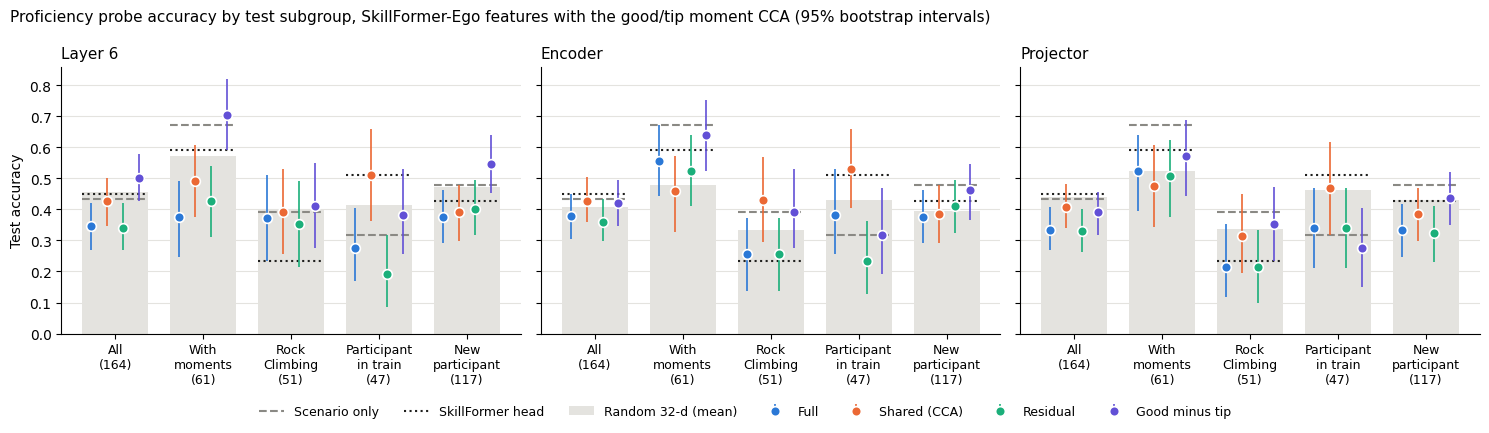

In [8]:
import matplotlib.pyplot as plt

PART_COLORS = {"full": "#2a78d6", "shared": "#eb6834", "residual": "#1baf7a", "good minus tip": "#6250d6"}
NULL_COLOR, GRID_COLOR, BAND_COLOR = "#8a8984", "#e4e3df", "#e4e3df"
GROUP_LABELS = {"All": "All", "With moments": "With\nmoments", "Rock Climbing": "Rock\nClimbing",
                "Participant in train": "Participant\nin train", "New participant": "New\nparticipant"}

def style(ax):
    ax.grid(axis="y", color=GRID_COLOR, lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

groups = list(SUBGROUPS)
x = np.arange(len(groups))
offsets = dict(zip(PART_COLORS, np.linspace(-0.27, 0.27, len(PART_COLORS))))
fig, axes = plt.subplots(1, len(FEATURES), figsize=(5.0 * len(FEATURES), 4.0), sharey=True)
for ax, part in zip(axes, FEATURES):
    ax.bar(x, [summary_table[g, f"{part}: random"][0] for g in groups], width=0.75, color=BAND_COLOR, label="Random 32-d (mean)")
    for k, g in enumerate(groups):
        ax.plot([k - 0.375, k + 0.375], [summary_table[g, "scenario only"][0]] * 2, color=NULL_COLOR, lw=1.5, ls="--",
                label="Scenario only" if k == 0 else None)
        ax.plot([k - 0.375, k + 0.375], [summary_table[g, "SkillFormer (its own head)"][0]] * 2, color="#1f1f1d", lw=1.5,
                ls=":", label="SkillFormer head" if k == 0 else None)
    for p, color in PART_COLORS.items():
        values = np.array([summary_table[g, f"{part}: {p}"][0] for g in groups])
        bounds = np.array([summary_table[g, f"{part}: {p}"][1] for g in groups])
        ax.errorbar(x + offsets[p], values, yerr=[values - bounds[:, 0], bounds[:, 1] - values], ls="none", marker="o",
                    ms=7, color=color, markeredgecolor="white", markeredgewidth=1.2, elinewidth=1.2, capsize=0, label=PARTS[p])
    ax.set_xticks(x, [f"{GROUP_LABELS[g]}\n({SUBGROUPS[g].sum()})" for g in groups], fontsize=9)
    ax.set_title(part.capitalize(), loc="left", fontsize=11)
    style(ax)
axes[0].set_ylabel("Test accuracy")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=9, ncol=len(labels), loc="lower center", bbox_to_anchor=(0.5, -0.07))
fig.suptitle("Proficiency probe accuracy by test subgroup, SkillFormer-Ego features with the good/tip moment CCA "
             "(95% bootstrap intervals)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/skillformer_goodtip_probe_accuracy.png", dpi=200, bbox_inches="tight")
plt.show()